In [ ]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from nltk.tokenize import word_tokenize, TweetTokenizer
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

#nltk.download('punkt')
#nltk.download('stopwords')
#nltk.download('wordnet')
#nltk.download('omw-1.4')

df = pd.read_csv('Tweets.csv')

In [9]:
# 1. Tokenizer Comparison: Naive vs. Standard Tweet Tokenizer
sample_tweet = "@VirginAmerica I'm sooooo angry!!! 😠 Flight cancelled flightled. http://t.co/123 #badservice"

naive_tokens = sample_tweet.split() # Breaks on emojis and URLs, keeps punctuation
tweet_tokenizer = TweetTokenizer(strip_handles=True, reduce_len=True)
smart_tokens = tweet_tokenizer.tokenize(sample_tweet)

print("Naive Tokenizer:", naive_tokens)
print("Tweet Tokenizer:", smart_tokens)
# Justification: TweetTokenizer reduces "sooooo" to "sooo", strips handles (@), and isolates emojis for sentiment.

# 2. Stop-word Modification
stop_words_default = set(stopwords.words('english'))
# Removing negation words from stop words is critical so sentiment isn't flipped
negation_words = {'not', 'no', 'nor', 'don', "don't", 'ain', 'aren', "aren't", 'couldn', "couldn't", 'didn', "didn't", 'doesn', "doesn't"}
custom_stop_words = stop_words_default - negation_words

def clean_text(text, stop_words):
    tokens = tweet_tokenizer.tokenize(text.lower())
    # Remove URLs, punctuation, and purely numeric tokens, keep emojis and text
    tokens = [t for t in tokens if not re.match(r'^http\S+|^[^\w\s\U0001f600-\U0001f64f]+$|\d+', t)]
    return [t for t in tokens if t not in stop_words]

df['cleaned_tokens'] = df['text'].apply(lambda x: clean_text(x, custom_stop_words))

# 3. Stemming vs. Lemmatization
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

sample_words = ['flying', 'cancelled', 'delayed', 'worst', 'better', 'caring']
stemmed = [stemmer.stem(w) for w in sample_words]
lemmatized = [lemmatizer.lemmatize(w, pos='v') for w in sample_words]

print("Stemmed:", stemmed) # e.g., 'car' instead of 'care' (distorts meaning)
print("Lemmatized:", lemmatized) # Preserves dictionary context

df['lemmatized_text'] = df['cleaned_tokens'].apply(lambda x: ' '.join([lemmatizer.lemmatize(w) for w in x]))

# 4. Measuring Loss
original_vocab = set(' '.join(df['text']).split())
cleaned_vocab = set(' '.join(df['lemmatized_text']).split())
original_avg_len = df['text'].apply(lambda x: len(x.split())).mean()
cleaned_avg_len = df['cleaned_tokens'].apply(len).mean()
empty_tweets = len(df[df['cleaned_tokens'].map(len) == 0])

print(f"Vocab Loss: {len(original_vocab)} -> {len(cleaned_vocab)}")
print(f"Avg Length Drop: {original_avg_len:.1f} -> {cleaned_avg_len:.1f} words")
print(f"Tweets left empty by cleaning: {empty_tweets}")

Naive Tokenizer: ['@VirginAmerica', "I'm", 'sooooo', 'angry!!!', '😠', 'Flight', 'cancelled', 'flightled.', 'http://t.co/123', '#badservice']
Tweet Tokenizer: ["I'm", 'sooo', 'angry', '!', '!', '!', '😠', 'Flight', 'cancelled', 'flightled', '.', 'http://t.co/123', '#badservice']
Stemmed: ['fli', 'cancel', 'delay', 'worst', 'better', 'care']
Lemmatized: ['fly', 'cancel', 'delay', 'worst', 'better', 'care']
Vocab Loss: 30105 -> 11888
Avg Length Drop: 17.7 -> 8.9 words
Tweets left empty by cleaning: 19


Top Distinctive Pos Words: [('thanks', np.float64(436.52825861824914)), ('thank', np.float64(332.69305267075316)), ('great', np.float64(159.48154089731352)), ('love', np.float64(101.47469656659865)), ('service', np.float64(98.02040367020098)), ('good', np.float64(89.21684106544947)), ('get', np.float64(87.06648802102741)), ('guy', np.float64(86.22329819242668)), ('airline', np.float64(80.90017369892341)), ('time', np.float64(80.0107625313769))]
Top Distinctive Neg Words: [('not', np.float64(891.0609490915291)), ('no', np.float64(793.7502518450565)), ('hour', np.float64(659.2169546319267)), ('get', np.float64(631.7171328682452)), ('cancelled', np.float64(540.7100831188442)), ('time', np.float64(507.1281828262594)), ('customer', np.float64(493.1865830354724)), ('service', np.float64(485.05258760016335)), ('bag', np.float64(454.7267306540944)), ('plane', np.float64(416.82238403607414))]
Top Negative N-Grams: [('customer service', np.int64(457)), ('cancelled flightled', np.int64(448)), ('c

C:\Users\Pc\AppData\Local\Temp\ipykernel_24644\1798096766.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[x[1] for x in neg_top10], y=[x[0] for x in neg_top10], palette='Blues_r')


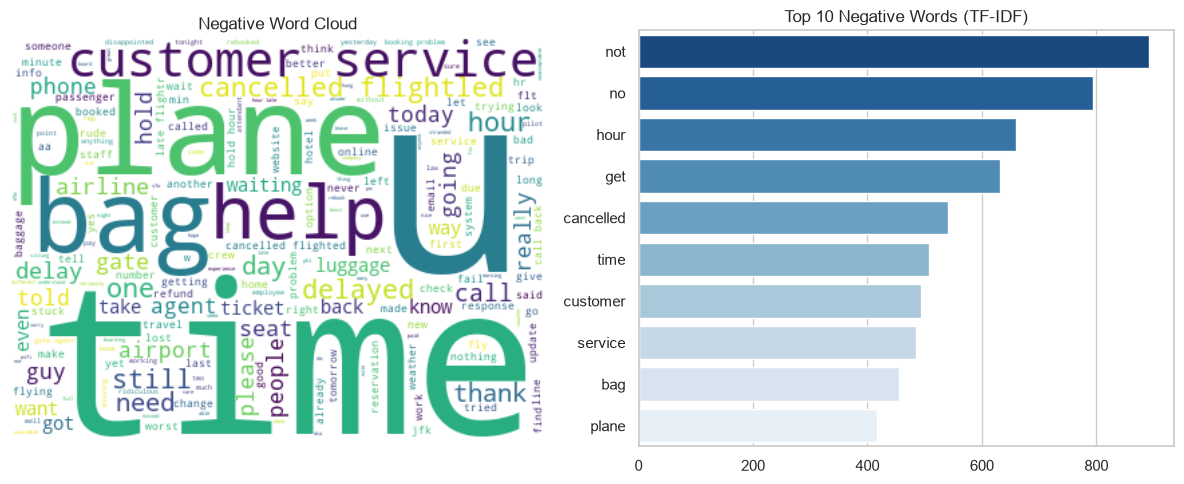

In [10]:
# 1. Fixing Airline Name Dominance
airline_names = {'united', 'usairways', 'americanair', 'southwestair', 'jetblue', 'virginamerica', 'flight'}
def remove_airlines(text):
    return ' '.join([w for w in text.split() if w not in airline_names])

df['analysis_text'] = df['lemmatized_text'].apply(remove_airlines)

# 2. Words separating Positive and Negative (TF-IDF vs Raw Frequency)
# Raw frequency shares generic terms. TF-IDF highlights distinctive terms.
tfidf = TfidfVectorizer(max_features=20)
pos_tweets = df[df['airline_sentiment'] == 'positive']['analysis_text']
neg_tweets = df[df['airline_sentiment'] == 'negative']['analysis_text']

# Function to get top TF-IDF words
def get_top_tfidf(text_series, title):
    matrix = tfidf.fit_transform(text_series)
    scores = zip(tfidf.get_feature_names_out(), np.asarray(matrix.sum(axis=0)).ravel())
    top_words = sorted(scores, key=lambda x: x[1], reverse=True)[:10]
    return top_words

print("Top Distinctive Pos Words:", get_top_tfidf(pos_tweets, "Positive"))
print("Top Distinctive Neg Words:", get_top_tfidf(neg_tweets, "Negative"))

# 3. N-Grams for Operational Problems
vectorizer_bigram = CountVectorizer(ngram_range=(2, 3), max_features=15)
neg_matrix = vectorizer_bigram.fit_transform(neg_tweets)
neg_freq = zip(vectorizer_bigram.get_feature_names_out(), np.asarray(neg_matrix.sum(axis=0)).ravel())
print("Top Negative N-Grams:", sorted(neg_freq, key=lambda x: x[1], reverse=True))
# Look for phrases like "customer service", "hold hour", "cancelled flight" (operational)
# Look for "not good" or "never fly" (sentiment flip)

# 4. Word Cloud vs Bar Chart
plt.figure(figsize=(12, 5))
# Word Cloud
plt.subplot(1, 2, 1)
wc = WordCloud(background_color='white', width=400, height=300).generate(' '.join(neg_tweets))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Negative Word Cloud')

# Bar Chart
plt.subplot(1, 2, 2)
neg_top10 = sorted(zip(tfidf.get_feature_names_out(), np.asarray(tfidf.fit_transform(neg_tweets).sum(axis=0)).ravel()), key=lambda x: x[1], reverse=True)[:10]
sns.barplot(x=[x[1] for x in neg_top10], y=[x[0] for x in neg_top10], palette='Blues_r')
plt.title('Top 10 Negative Words (TF-IDF)')
plt.tight_layout()
plt.show()
# Justification: The bar chart provides precise counts and ranks, whereas the word cloud is subjective and layout-dependent.

In [11]:
# 1. Score tweets with VADER and compare with human labels
analyzer = SentimentIntensityAnalyzer()

def get_vader_label(text):
    score = analyzer.polarity_scores(text)['compound']
    if score >= 0.05: return 'positive'
    elif score <= -0.05: return 'negative'
    else: return 'neutral'

df['vader_sentiment'] = df['text'].apply(get_vader_label)
print("Classification Report (Human vs VADER):\n", classification_report(df['airline_sentiment'], df['vader_sentiment']))

# 2. Find major disagreements (e.g., Human=Negative, VADER=Positive)
disagreements = df[(df['airline_sentiment'] == 'negative') & (df['vader_sentiment'] == 'positive')]
print("Sample Disagreements:\n", disagreements['text'].head(5).values)
# Analysis: Look for sarcasm ("Great, delayed again!"), negation ("Not exactly a good flight"), or industry terms ("delay").

# 3. Three tricky custom tweets
custom_tweets = [
    "Oh brilliant, another 3 hour delay. Exactly what I wanted.", # Sarcasm
    "The flight was not a complete disaster.", # Negation / Mixed
    "My flight got cancelled but the gate agent was an absolute angel." # Mixed feelings / Operational failure
]
for ct in custom_tweets:
    print(f"Tweet: {ct} | VADER Score: {analyzer.polarity_scores(ct)['compound']}")

# 4. Filter by High Confidence
high_conf_df = df[df['airline_sentiment_confidence'] > 0.9]
print("\nHigh Confidence Classification Report:\n", classification_report(high_conf_df['airline_sentiment'], high_conf_df['vader_sentiment']))

Classification Report (Human vs VADER):
               precision    recall  f1-score   support

    negative       0.90      0.44      0.59      9178
     neutral       0.39      0.32      0.35      3099
    positive       0.28      0.91      0.43      2363

    accuracy                           0.49     14640
   macro avg       0.52      0.56      0.46     14640
weighted avg       0.69      0.49      0.51     14640

Sample Disagreements:
 <StringArray>
[  '@VirginAmerica  I flew from NYC to SFO last week and couldn't fully sit in my seat due to two large gentleman on either side of me. HELP!',
 '@VirginAmerica you guys messed up my seating.. I reserved seating with my friends and you guys gave my seat away ... 😡 I want free internet',
               '@VirginAmerica amazing to me that we can't get any cold air from the vents. #VX358 #noair #worstflightever #roasted #SFOtoBOS',
              '@VirginAmerica help, left expensive headphones on flight 89 IAD to LAX today. Seat 2A. No one 

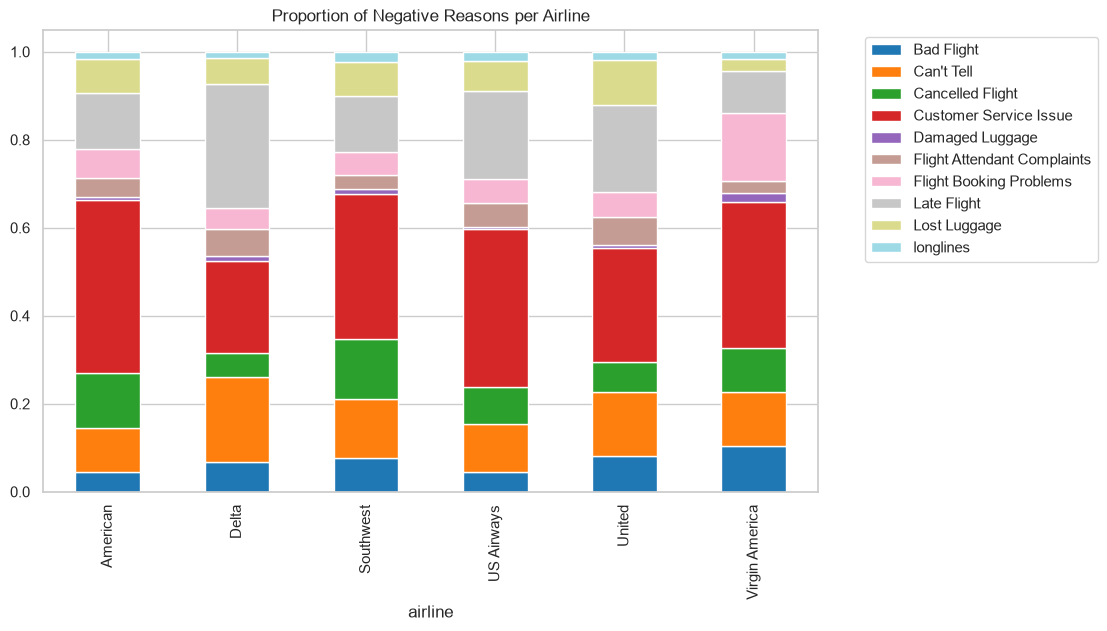

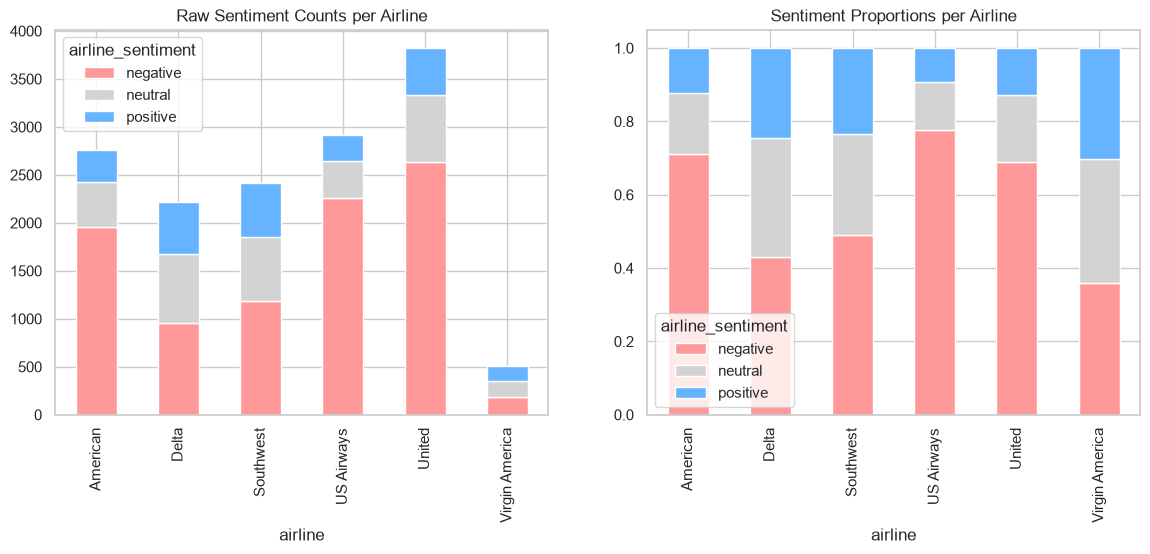

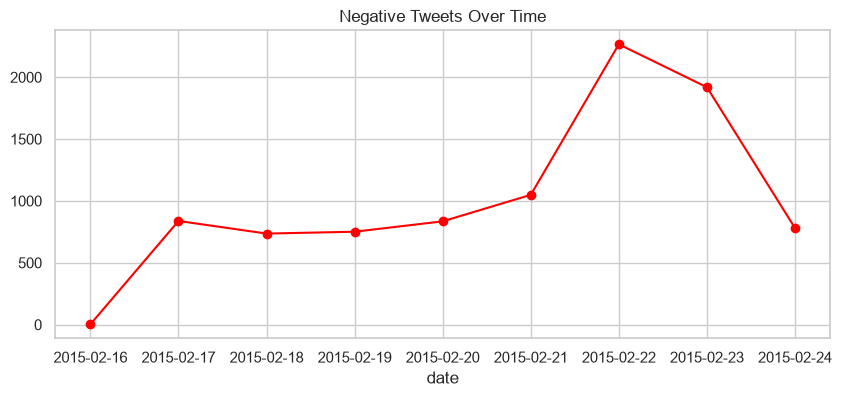

In [13]:
# 1. Customer Service vs. Operational Complaints
if 'negativereason' in df.columns:
    reasons = df.groupby(['airline', 'negativereason']).size().unstack().fillna(0)
    reasons.div(reasons.sum(axis=1), axis=0).plot(kind='bar', stacked=True, figsize=(10,6), cmap='tab20')
    plt.title("Proportion of Negative Reasons per Airline")
    plt.legend(bbox_to_anchor=(1.05, 1))
    plt.show()

# 2. Overall Sentiment Totals: Raw Count vs Proportion
sentiment_counts = df.groupby(['airline', 'airline_sentiment']).size().unstack()
sentiment_props = sentiment_counts.div(sentiment_counts.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sentiment_counts.plot(kind='bar', stacked=True, ax=axes[0], color=['#ff9999','#d3d3d3','#66b3ff'])
axes[0].set_title('Raw Sentiment Counts per Airline')

sentiment_props.plot(kind='bar', stacked=True, ax=axes[1], color=['#ff9999','#d3d3d3','#66b3ff'])
axes[1].set_title('Sentiment Proportions per Airline')
plt.show()
# Report Choice: Proportions prevent volume-heavy airlines (like United) from automatically looking like the worst performers.

# 3. Time Series Analysis
df['tweet_created'] = pd.to_datetime(df['tweet_created'])
df['date'] = df['tweet_created'].dt.date
time_series = df[df['airline_sentiment']=='negative'].groupby('date').size()
time_series.plot(figsize=(10, 4), color='red', marker='o')
plt.title("Negative Tweets Over Time")
plt.grid(True)
plt.show()
# Explaining spikes: Cross-reference dates with historical weather events (e.g., Feb 2015 winter storms).

# 4. Prioritization Rule
# Rule: Negative sentiment + High Retweet Count + Low follower count (to stop viral spread early) OR specific trigger words ("stranded", "lost bag").
df['priority_score'] = (df['vader_sentiment'] == 'negative').astype(int) * (df['retweet_count'] + 1)
priority_tweets = df.sort_values(by='priority_score', ascending=False).head(5)

1. How the dataset could mislead:

Selection Bias: Twitter users skew younger, more tech-savvy, and more vocal than the average passenger. Quiet, satisfied passengers rarely tweet.   

Context Collapse: The dataset does not link tweets to actual flight logs, meaning a single cancelled flight with 50 angry tweeters looks like 50 separate systemic failures.

Survivor Bias: Tweets deleted by users or removed by Twitter before the scrape are missing.Least trusted finding: Absolute sentiment ratios. Twitter is inherently a complaint platform for airlines; a 70% negative tweet ratio does not mean 70% of all passengers are unhappy.

2. 2015 vs. Today:

In 2015, chatbots and in-app support were nascent. Today, automated DMs catch many complaints before they become public tweets. The public timeline now likely contains more extreme escalations rather than basic "where is my bag?" queries.

3. Tool vs. Manual Team:

Recommendation: Do not replace the team entirely. Use the automated tool as a triage system. As seen in Part C, VADER struggles with sarcasm and industry-specific context ("delayed" is just a word to VADER, but a ruined trip to a human). The tool should tag and route high-priority operational complaints to the manual team for immediate intervention.

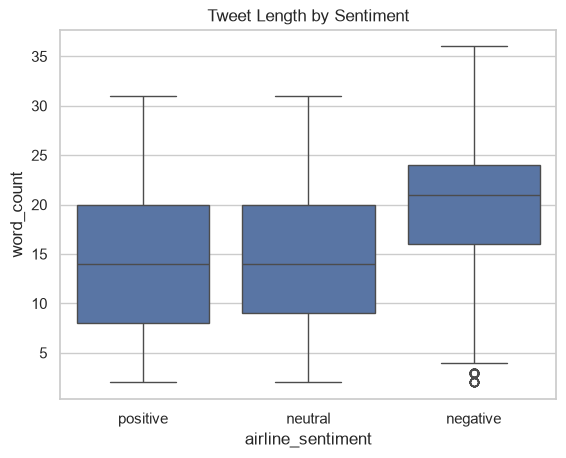

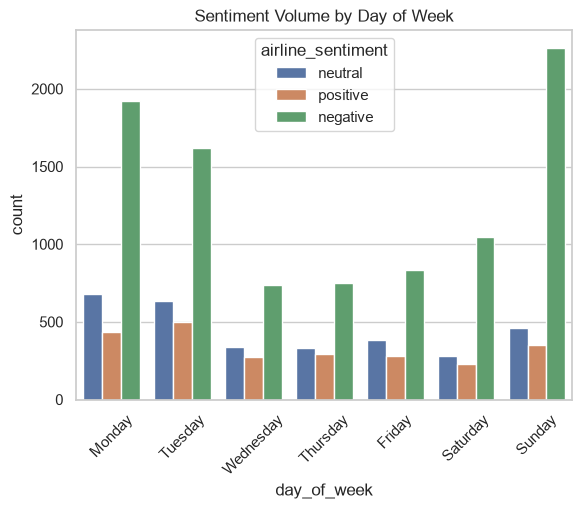

In [14]:
# Insight 1: Does tweet length correlate with anger?
df['word_count'] = df['text'].apply(lambda x: len(x.split()))
sns.boxplot(x='airline_sentiment', y='word_count', data=df, order=['positive', 'neutral', 'negative'])
plt.title("Tweet Length by Sentiment")
plt.show()

# Insight 2: Day of the week impact
df['day_of_week'] = df['tweet_created'].dt.day_name()
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(x='day_of_week', hue='airline_sentiment', data=df, order=day_order)
plt.title("Sentiment Volume by Day of Week")
plt.xticks(rotation=45)
plt.show()

1. Verbosity as an Indicator of Frustration

Observation: Negative tweets are consistently longer and closer to the character limit than positive tweets.

Evidence: The boxplot of word_count by airline_sentiment shows a higher median and tighter cluster near the maximum length for negative tweets.

Why it matters: Customers aren't just dropping quick complaints; they are taking the time to detail their poor experiences.

Recommended action: Use text length as a secondary feature in the routing algorithm. Long, negative tweets should be bumped up the queue for human review.

Confidence and limits: High confidence in the correlation, but character limits have changed since 2015, which would alter the exact distribution today.

2. The Sunday/Monday Operational Squeeze

Observation: Negative sentiment spikes specifically on Sundays and Mondays.

Evidence: The count plot of sentiment by day_of_week reveals a disproportionate volume of negative tweets at the start of the week.

Why it matters: This aligns with the end of weekend travel and the start of business travel, where delays have the highest compounding effect on schedules.

Recommended action: Staff the customer service social media desks heavier on Sunday evenings and Monday mornings.

Confidence and limits: Medium confidence; the 2015 dataset is limited to a narrow date range, so this could be an artifact of a specific weather event rather than a year-round trend.